In [58]:
import pandas as pd

In [59]:
import matplotlib.pyplot as plt

In [60]:
import os

# Check current directory
print("Before:", os.getcwd())

Before: C:\Users\graem


In [61]:
df_train = pd.read_csv(r"C:\Users\graem\OneDrive\Documents\Algonquin\Fall Semester\CST8504 - AI Techniques\dir\train.csv")
df_test = pd.read_csv(r"C:\Users\graem\OneDrive\Documents\Algonquin\Fall Semester\CST8504 - AI Techniques\dir\test.csv")
df_validation = pd.read_csv(r"C:\Users\graem\OneDrive\Documents\Algonquin\Fall Semester\CST8504 - AI Techniques\dir\validation.csv")

In [62]:
df_train

,Unnamed: 0,TenYearCHD,male,age,currentSmoker,prevalentStroke,prevalentHyp,diabetes,education_1.0,education_2.0,...,heartRate_Group_Low,heartRate_Group_Normal,heartRate_Group_Elevated,heartRate_Group_Very High,heartRate_Group_Not Known,glucose_Group_Low,glucose_Group_Normal,glucose_Group_Prediabetic,glucose_Group_Diabetic Range,glucose_Group_Very High
0,4097,0,1,54,1,0,0,0,0,1,...,0,1,0,0,0,0,1,0,0,0
1,3165,0,1,44,1,0,0,0,0,0,...,0,1,0,0,0,0,1,0,0,0
2,2499,1,0,46,1,0,0,0,0,1,...,0,1,0,0,0,1,0,0,0,0
3,3345,0,1,38,1,0,0,0,0,1,...,1,0,0,0,0,0,1,0,0,0
4,3596,0,1,40,1,0,0,0,0,1,...,1,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2963,3444,0,0,36,1,0,1,0,1,0,...,0,1,0,0,0,0,1,0,0,0
2964,466,0,0,57,1,0,0,0,0,0,...,0,1,0,0,0,0,1,0,0,0
2965,3092,0,0,60,0,0,1,0,0,1,...,0,1,0,0,0,0,1,0,0,0
2966,3772,0,1,39,1,0,0,0,0,1,...,0,1,0,0,0,1,0,0,0,0


In [63]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


In [64]:
X_train = df_train.drop(columns=['TenYearCHD'])
y_train = df_train['TenYearCHD']

X_test = df_test.drop(columns=['TenYearCHD'])
y_test = df_test['TenYearCHD']

X_validation = df_validation.drop(columns=['TenYearCHD'])
y_validation = df_validation['TenYearCHD']


In [65]:
model = DecisionTreeClassifier(max_depth=5, random_state=42, min_samples_split=3, min_samples_leaf=3)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))   # precision, recall, F1, accuracy
print(confusion_matrix(y_test, y_pred))

Test Accuracy: 0.8301886792452831
              precision    recall  f1-score   support

           0       0.84      0.98      0.91       537
           1       0.09      0.01      0.02        99

    accuracy                           0.83       636
   macro avg       0.47      0.50      0.46       636
weighted avg       0.73      0.83      0.77       636

[[527  10]
 [ 98   1]]


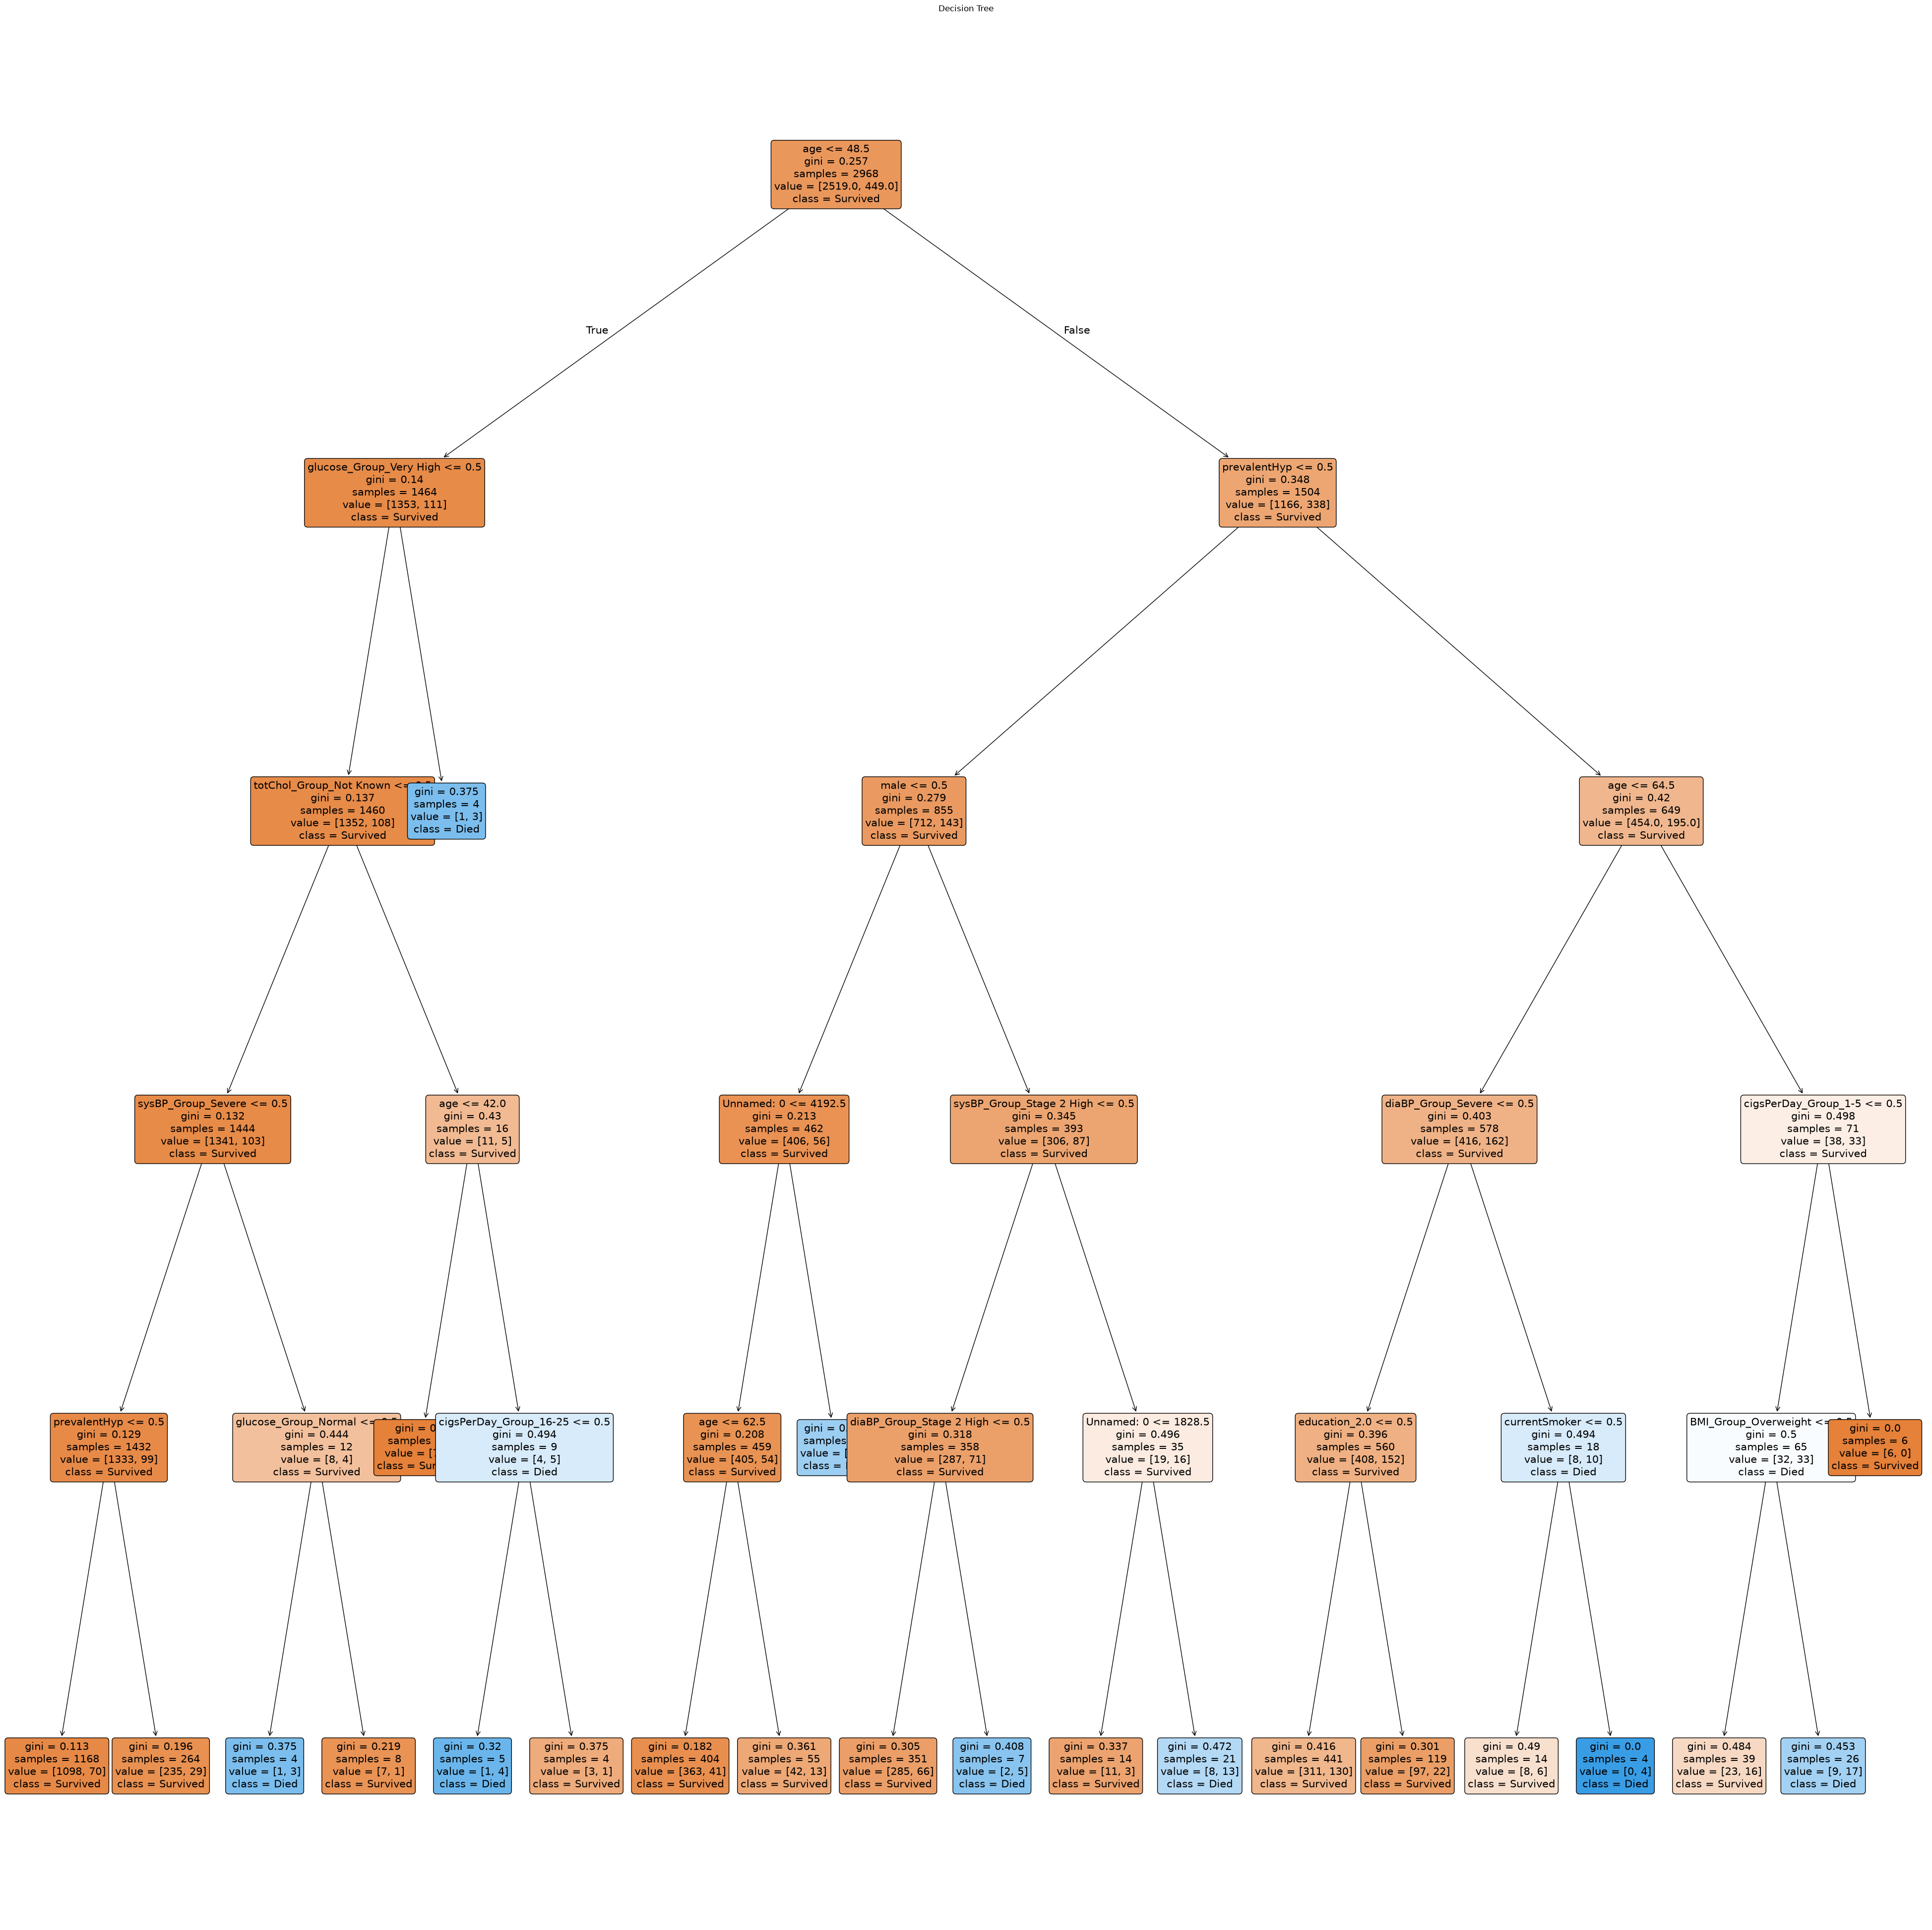

In [66]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Plot the decision tree
plt.figure(figsize=(50, 50))

plot_tree(
    model,
    feature_names=X_train.columns,
    class_names=['Survived', 'Died'],
    filled=True,
    rounded=True,
    fontsize=15
)

plt.title("Decision Tree")
plt.show()